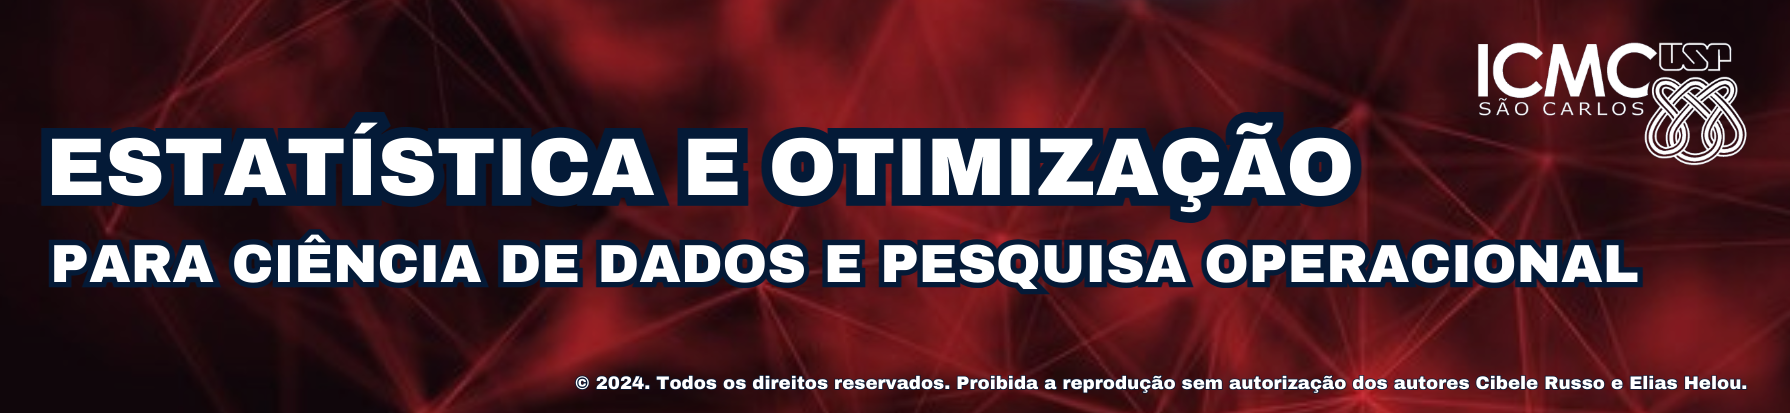

<h1 style = 'text-align: center;'>Otimização Não-Linear:<br>Fundamentos</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do vídeo</h2>

1. Otimização não-linear

2. Gradientes e Hessianas

3. O pacote `sympy`

## 1. Otimização Não-Linear

A forma geral de um problema de otimização não-linear é
$$\def\vect{\boldsymbol}
    \begin{align*}
        \min       & \quad f( \vect x )\\
        \text{s.a:}& \quad g_i( \vect x ) \le 0 & i \in \{ 1, 2, \dots, p \}\phantom.\\
                   & \quad h_j( \vect x ) = 0   & j\in \{ 1, 2, \dots, q \}.
    \end{align*}
$$

As funções envolvidas são da forma
$$\def\vect{\boldsymbol}
    \begin{align*}
        &f( \vect x ) : \mathbb R^n \to \mathbb R &\\
        &g_i( \vect x ) : \mathbb R^n \to \mathbb R &\quad i \in \{ 1, 2, \dots, p \}\phantom.\\
        &h_j( \vect x ) : \mathbb R^n \to \mathbb R &\quad j \in \{ 1, 2, \dots, q \}.        
    \end{align*}
$$


### 1.1. Continuidade e Diferenciabilidade

Todas as funções neste módulo serão contínuas. Muitas vezes serão diferenciáveis.

Informalmente:

- Uma função contínua não possui saltos

- Uma função diferenciável parece uma função afim

Por exemplo, a função
$$
    f( x ) = x^2
$$
é diferenciável em todos os pontos.

No ponto $x = -1$, ela pode ser aproximada "arbitrariamente bem" pela sua reta tangente, dada por
$$
    f( x ) = -2x - 1.
$$

<div style="text-align: center;">
    <iframe type="text/html" src="https://www.desmos.com/calculator?lang=pt-BR" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px">
</div>

Já a função módulo não é diferenciável em $0$
$$
    | x | = \begin{cases}
                -x & \text{se } x < 0\\
                \phantom{-{}}x & \text{caso contrário.}
            \end{cases}
$$

<div style="text-align: center;">
    <iframe type="text/html" src="https://www.desmos.com/calculator?lang=pt-BR" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px">
</div>

Já a função escada sequer é contínua
$$
    s( x ) = \begin{cases}
                0 & \text{se } x < 0\\
                1 & \text{caso contrário.}
            \end{cases}
$$

<div style="text-align: center;">
    <iframe type="text/html" src="https://www.desmos.com/calculator?lang=pt-BR" width="90%" height="500" style="text-align: center; border: solid; border-radius: 10px">
</div>

Observações:

- funções diferenciáveis podem ser aproximadas por funções afins (lineares mais uma constante)

- funções não-diferenciáveis não são tão fáceis de serem aproximadas por funções mais simples

- funções descontínuas impossibilitam o reconhecimento de otimizadores locais

Neste módulo, iremos considerar funções diferenciáveis ou, no máximo, não-diferenciáveis simples.

## 2. Gradientes e Hessianas

### 2.1. Gradientes

O conceito de gradiente tem importância fundamental em otimização

- Gradientes podem ser usados para testar se um ponto é candidato a minimizador

- Gradientes são úteis para encontrar direções que algoritmos devem seguir

- Gradientes podem ser calculados para problemas de grande porte

- Gradientes são o equivalente a derivadas para funções multivariadas

O gradiente $\def\vect{\boldsymbol}\nabla f( \vect x )$ de uma função $f : \mathbb R^n \to \mathbb R$ em um ponto $\vect x \in \mathbb R^n$ é definido como

$$
	\nabla f( \vect x ) = \begin{pmatrix}
		\displaystyle\frac{\partial f}{\partial x_1}( \vect x )\\[1em]
		\displaystyle\frac{\partial f}{\partial x_2}( \vect x )\\[1em]
		\vdots\\[1em]
		\displaystyle\frac{\partial f}{\partial x_n}( \vect x )
	\end{pmatrix},
$$
onde $\displaystyle\frac{\partial f}{\partial x_i}$ é a derivada parcial de $f$ com relação a $x_i$.

Vejamos alguns exemplos de gradientes

#### 2.1.1. Função de Rosenbrock

Por exemplo, considere a função de Rosenbrock
$$\def\vect{\boldsymbol}
    f( \vect x ) = ( 1 - x_1 )^2 + ( x_2 - x_1^2 )^2.
$$

O seu gradiente é dado por

$$\def\vect{\boldsymbol}
    \nabla f( \vect x ) = \begin{pmatrix}
                             2( x_1 - 1 ) + 4x_1( x_1^2 - x_2 )\\
                             2( x_2 - x_1^2 )
                          \end{pmatrix}.
$$

#### 2.1.2. Quadrados Mínimos

A função de quadrados mínimos (linear) é dada por

$$\def\vect{\boldsymbol}
    f( \vect x ) = \frac12\| A\vect x - \vect b \|_2^2,
$$
onde $A \in \mathbb R^{m\times n}$ e $\vect b \in \mathbb R^m$ são dados.

Seu gradiente pode ser calculado e tem a forma a seguir:
$$
    \nabla f( \vect x ) = A^TA\vect x - A^T\vect b.
$$


#### 2.1.3. Área da Lata

A função da área da lata, dada por
$$
    A( a, r ) = 2\pi r^2 + 2\pi ra = 2\pi r( r + a )
$$

tem como gradiente
$$
    \nabla A( a, r ) = \begin{pmatrix}
                             2\pi r\\
                             2\pi(2r + a)
                       \end{pmatrix}.
$$


### 2.2. Hessianas

A matriz hessiana é a generalização da segunda derivada para o caso de funções multivariadas. Definimos a hessiana $\def\vect{\boldsymbol}\nabla^2 f( \vect x )$ de uma função $f : \mathbb R^n \to \mathbb R$ em um ponto $\vect x \in \mathbb R^n$ como

$$
	\nabla^2f( \vect x ) = \begin{bmatrix}
		\displaystyle\frac{\partial^2 f}{\partial x_1^2}( \vect x ) & \displaystyle\frac{\partial^2 f}{\partial x_1\partial x_2}( \vect x ) & \cdots & \displaystyle\frac{\partial^2 f}{\partial x_1\partial x_n}( \vect x )\\[1em]
		\displaystyle\frac{\partial^2 f}{\partial x_2\partial x_1}( \vect x ) & \displaystyle\frac{\partial^2 f}{\partial x_2^2}( \vect x ) & \cdots & \displaystyle\frac{\partial^2 f}{\partial x_2\partial x_n}( \vect x )\\[1em]
		\vdots & \vdots & \ddots & \vdots \\[1em]
		\displaystyle\frac{\partial^2 f}{\partial x_n\partial x_1}( \vect x ) & \displaystyle\frac{\partial^2 f}{\partial x_n\partial x_2}( \vect x ) & \cdots & \displaystyle\frac{\partial^2 f}{\partial x_n^2}( \vect x )
	\end{bmatrix},
$$

onde $\displaystyle \frac{\partial^2 f}{\partial x_i\partial x_j}( \vect x )$ denota as derivadas parciais com relação às variáveis $x_j$ e $x_i$ em sequência.

É incomum o uso da hessiana na solução ou análise de problemas de otimização em grande escala, mas ela pode ser útil em algumas circunstâncias.

## 3. O Pacote `sympy`

Uma fonte comum de erros ao resolver problemas de otimização é o cálculo do gradiente. Atualmente, é possível usar ferramentas de diferenciação automática (muito usadas em aprendizado profundo) ou diferenciação simbólica para automatizar essa tarefa

O `sympy`é um pacote que fornece diversas ferramentas para computação simbólica, inclusive diferenciação.

In [1]:
import sympy as sp

x_1, x_2 = sp.symbols( 'x_1, x_2' )

ros = ( 1 - x_1 ) ** 2 + ( x_2 - x_1 ** 2 ) ** 2

In [2]:
ros

(1 - x_1)**2 + (-x_1**2 + x_2)**2

In [3]:
sp.diff( ros, x_1 )

-4*x_1*(-x_1**2 + x_2) + 2*x_1 - 2

In [4]:
sp.factor( sp.diff( ros, x_1 ) )

2*(2*x_1**3 - 2*x_1*x_2 + x_1 - 1)

In [5]:
sp.simplify( sp.diff( ros, x_1 ) )

4*x_1*(x_1**2 - x_2) + 2*x_1 - 2

In [6]:
sp.factor( sp.diff( ros, x_2 ) )

-2*(x_1**2 - x_2)

In [7]:
a, r = sp.symbols( 'a, r' )

A = 2 * sp.pi * r * ( r + a )

A

2*pi*r*(a + r)

In [8]:
sp.diff( A, a )

2*pi*r

In [9]:
sp.diff( A, r )

2*pi*r + 2*pi*(a + r)

In [10]:
sp.factor( sp.diff( A, r ) )

2*pi*(a + 2*r)

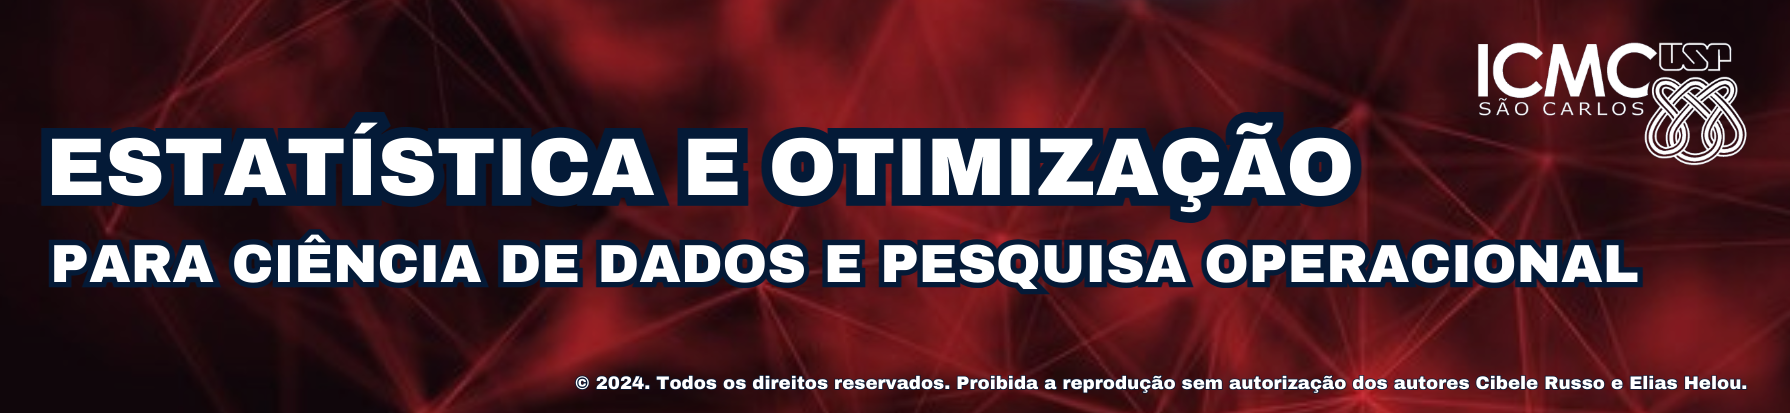

<h1 style = 'text-align: center;'>Otimização Não-Linear:<br>Método de Máxima Descida</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Direção de máxima descida

2. Método de máxima descida

3. Minimizando a função de Rosenbrock

## 1. Direção de Máxima Descida

Dada uma função diferenciável $f : \mathbb R^n \to \mathbb R$, a direção de máxima descida a partir de um ponto $\def\vect{\boldsymbol}x \in \mathbb R^n$ é o negativo do gradiente:
$$
    \vect d = -\nabla f( \vect x ).
$$

Esta direção é a que **localmente** reduz mais rapidamente o valor da função objetivo.

Em geral, uma direção é dita de descida se ela localmente reduz o valor da função objetivo. Dada uma direção $\vect d \in \mathbb R^n$, se a condição abaixo for satisfeita, ela é uma direção de descida para $f$ a partir de $\vect x$:
$$
    \vect d^T\nabla f( \vect x ) < 0.
$$

### 1.1. Condição Necessária de Primeira Ordem

Observe que se o gradiente não for nulo em um dado ponto $\vect x$, então sempre podemos reduzir o valor da função objetivo indo na direção $-\nabla f( \vect x )$.


De fato, uma condição necessária para otimalidade de um ponto $\vect x^*$ é que o gradiente se anule em $\vect x^*$:
$$
    \nabla f( \vect x^* ) = \vect 0.
$$

## 2. Método de Máxima Descida

O método de máxima descida possui diversos nomes:

- Método de máxima descida

- Método de descida do gradiente

- Método do gradiente

Considere o problema de minimizção sem restrições
$$\Large
    \min\quad f( \vect x ).
$$

Para resolver este problema, o método de máxima descida é um algoritmo iterativo, como todos em otimização não-linear, com a seguinte forma
$$\Large
    \vect x^{( k + 1 )} = \vect x^{( k )} - \lambda \nabla f( \vect x^{( k )} ).
$$

Nas iterações acima, $\lambda > 0$ é o tamanho de passso. Este tamanho de passo pode variar dentre as iterações, mas iremos discutir apenas o caso em que ele se mantém fixo.

O método de máxima descida com passo fixo pode ser útil em aplicações onde o número de variáveis é gigante, mas em geral há alternativas melhores.

Sua principal utilidade é auxiliar na compreensão dos fundamentos de otimização não-linear.

- Se a função $f$ é diferenciável e tem um gradiente suave, o método converge

- A convergência é garantida para tamanhos de passo suficientemente pequenos

- O método está dentre os que usam menos recursos computacionais a cada iteração

- É muito fácil de implementar

- Leva muitas iterações pra convergir

- Não funciona para problemas com restrições

## 3. Minimizando a Função de Rosenbrock

Vamos minimizar a função de Rosenbrock usando o método de máxima descida

Lembremos da função de Rosenbrock:
$$
    f( \vect x ) = ( 1 - x_1 )^2 + ( x_2 - x_1^2 )^2.
$$

Observe que o minimizador é $( x_1, x_2 ) = ( 1, 1 )$.

Abaixo vemos uma representação gráfica desta função.

In [ ]:
import numpy as np
import matplotlib.pyplot as pp

def rosenbrock( X, Y ):

    return ( 1.0 - X ) ** 2 + ( Y - X ** 2 ) ** 2

x = np.linspace( -1.0, 3.0, 200 )
X = np.tile( x, ( len( x ), 1 ) )
Y = X.T

Z = rosenbrock( X, Y )

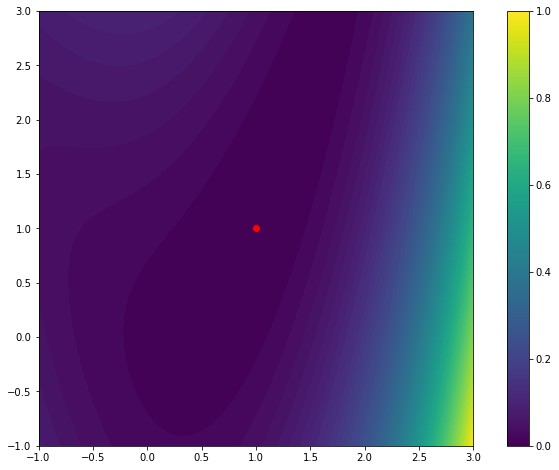

In [ ]:
pp.figure( figsize = ( 10, 8 ) )
pp.contourf( X, Y, Z, extent = ( X.min(), X.max(), Y.min(), Y.max() ), levels = 100 )
pp.scatter( 1, 1, zorder = 10, c = 'r' )
pp.colorbar()
pp.axis( 'square' )
pp.show()

### 3.1. Implementando o Gradiente

Como já dito, a implementação do gradiente deve ser feita cuidadosamente. O gradiente de nossa função é dado por
$$
    \nabla f( \vect x ) = \begin{pmatrix}
                             2( x_1 - 1 ) + 4x_1( x_1^2 - x_2 )\\
                             2( x_2 - x_1^2 )
                          \end{pmatrix}.
$$

Abaixo temos uma implementação deste gradiente.

In [ ]:
def rosenbrock_grad( x ):

    return np.array(
        (
            2 * ( x[ 0 ] - 1 ) + 4 * x[ 0 ] * ( x[ 0 ] ** 2 - x[ 1 ] ),
            2 * ( x[ 1 ] - x[ 0 ] ** 2 )
        )
    )

### 3.2. Implementando o Método de Máxima Descida

In [ ]:
def md( grad, x, l, n ):

    iters = [ x ]

    for i in range( n ):

        x = x - l * grad( x )
        iters.append( x )

    return iters

In [ ]:
iters = md( rosenbrock_grad, np.zeros( ( 2, ) ), 1.0e-1, 300 )
print( iters[ -1 ] )

[0.9999916  0.99997972]


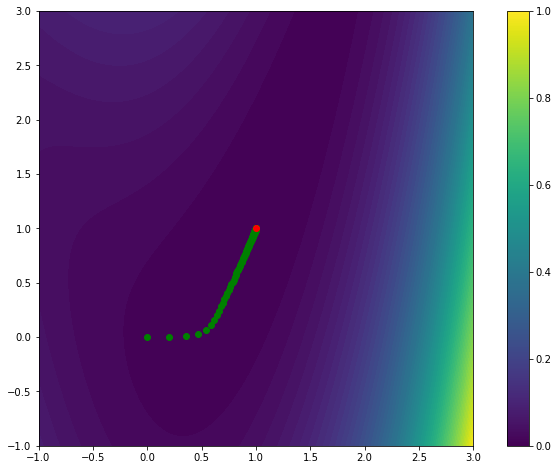

In [ ]:
pp.figure( figsize = ( 10, 8 ) )
pp.contourf( X, Y, Z, extent = ( X.min(), X.max(), Y.min(), Y.max() ), levels = 100 )
pp.scatter( 1, 1, zorder = 10, c = 'r' )
for x in iters:
    pp.scatter( x[ 0 ], x[ 1 ], zorder = 9, c = 'g' )
pp.colorbar()
pp.axis( 'square' )
pp.show()

In [ ]:
iters = md( rosenbrock_grad, np.zeros( ( 2, ) ), 1.0, 300 )
print( iters[ -1 ] )

[nan nan]


/tmp/ipykernel_29532/2727906609.py:5: RuntimeWarning: overflow encountered in scalar multiply
  2 * ( x[ 0 ] - 1 ) + 4 * x[ 0 ] * ( x[ 0 ] ** 2 - x[ 1 ] ),
/tmp/ipykernel_29532/3424597130.py:7: RuntimeWarning: invalid value encountered in subtract
  x = x - l * grad( x )


Observações:

- Levamos muitas iterações

- É preciso escolher o tamanho de passo com cuidado

- A implementação é simples

- Converge para minimizadores locais

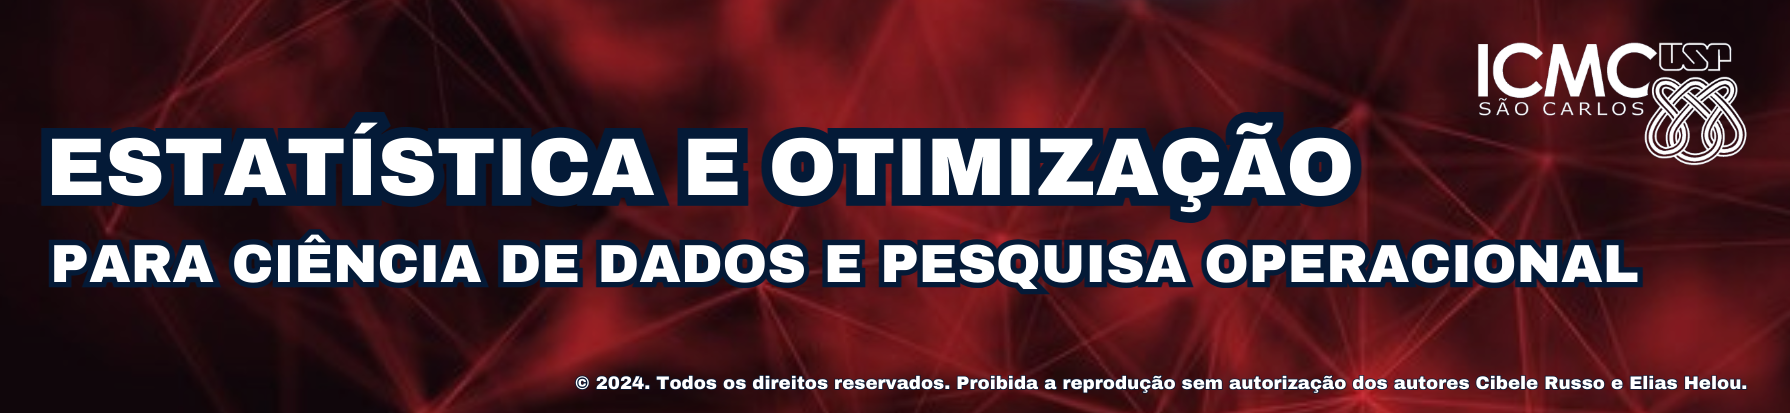

<h1 style = 'text-align: center;'>Otimização Não-Linear:<br>Uma Aplicação em Imagens</h1>

por **Elias Helou**

**ICMC/USP - São Carlos SP**

<h2>Conteúdo do Vídeo</h2>

1. Máxima descida para quadrados mínimos

2. O problema da imagem desfocada

3. Solução com máxima descida

<h2>1. Máxima Descida para Quadrados Mínimos</h3>

Para o problema de quadrados mínimos
$$\def\vect{\boldsymbol}
    \min_{\vect x \in \mathbb R^n} \quad f( \vect x ) = \frac12 \| A\vect x - \vect b \|_2^2,
$$
temos
$$
    \nabla f( \vect x ) = A^TA\vect x - A^T\vect b = A^T( A\vect x - \vect b ).
$$

Ou seja, o método de máxima descida
$$
    \vect x^{( k + 1 )} = \vect x^{ ( k ) } - \lambda \nabla f( \vect x^{ ( k ) } )
$$
assume a forma
$$
    \vect x^{( k + 1 )} = \vect x^{ ( k ) } - \lambda A^T( A\vect x^{ ( k ) } - \vect b ).
$$

Observe que não precisamos conhecer a matriz $A$. Precisamos saber os produtos matriz-vetor envolvendo $A$ e $A^T$.

## 2. O Problema da Imagem Desfocada

Neste exemplo,  os dados $\vect b$ serão os pixels de uma versão borrada de uma imagem desconhecida e desejamos obter a imagem original a partir da sua versão borrada.

Cada componente do vetor de variáveis de decisão $\vect x \in \mathbb R^n$ é a intensidade de um pixel da imagem desejada.

O operador $A$ é tal que se $\vect x$ é a imagem original, então $A\vect x$ é a versão borrada. Esta operação $\vect x \mapsto A\vect x$ é obtida através da _convolução_ da imagem com uma imagem constante, chamada de _kernel_ da convolução.

A adjunta $A^T$ da convolução é a _correlação_. Ambas operações estão implementadas no módulo `scipy.signal` através das funções `convolve` e `correlate`.

### 2.1. A Imagem de Teste

Principiamos por nossa imagem de teste, que é a foto de uma astronauta. Neste exemplo, usaremos uma versão monocromática da imagem original colorida. Esta imagem está disponível no módulo `skimage`:

262144


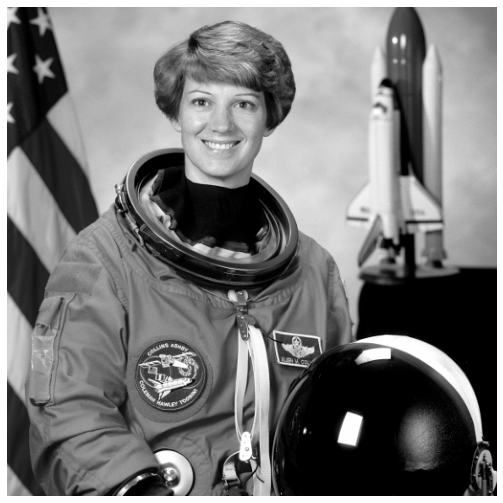

In [ ]:
import skimage as si              # Para os dados da imagem
import skimage.color as sc        # Para converter para monocromática
import matplotlib.pyplot as pp    # Para mostrar imagem e gráficos
import numpy as np                # Para rotinas numéricas
import scipy.signal as ss         # Para convolução e correlação

# Astronauta monocromática
img = sc.rgb2gray( si.data.astronaut() )

# O número de variáveis do problema
# é o número de pixels da imagem
print( np.prod( img.shape ) )

pp.figure( figsize = ( 9, 9 ) )
pp.imshow( img, cmap = pp.cm.gray )
pp.axis( 'off' )
pp.show()

### 2.2. Implementando os Produtos Matriz-Vetor

Agora iremos implementar as operações $\vect x \mapsto A\vect x$ e $\vect x \mapsto A^T\vect x$ em termos das funções `convolve` e `correlate`:

In [ ]:
# Atenção, são adjuntas somente se
# o tamanho do kernel é ímpar.
N_kernel = 7
kernel = np.full( ( N_kernel, N_kernel ), 1 / ( N_kernel ** 2 ) )

def A( x ):

    return ss.convolve( x, kernel, mode = 'same' )

def AT( x ):

    return ss.correlate( x, kernel, mode = 'same' )

Testa se $\vect y^T A \vect x = \vect x^T A^T\vect y:$

In [ ]:
x = np.random.standard_normal( size = img.shape )
y = np.random.standard_normal( size = img.shape )

print( ( y * A( x ) ).sum() )
print( ( x * AT( y ) ).sum() )

-102.93950528870022
-102.93950528870013


### 2.3. Geração dos Dados $\vect b$

Agora criaremos os dados $\vect b$, que são uma versão borrada da imagem original.

Note que, em uma aplicação real, teremos os dados, mas não a imagem que deu origem a eles.

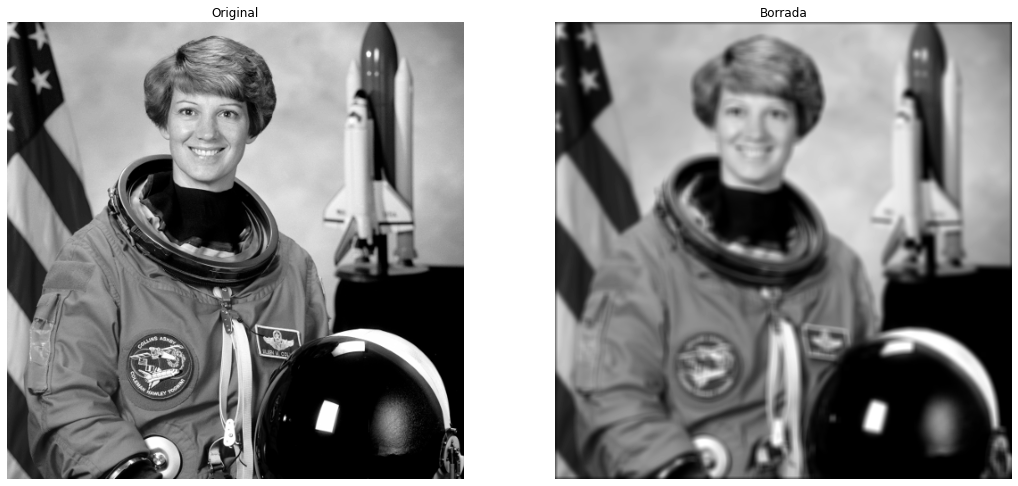

In [ ]:
# Cria imagem borrada:
b = A( img )

pp.figure( figsize = ( 18, 9 ) )

pp.subplot( 1, 2, 1 )
pp.imshow( img, cmap = pp.cm.gray )
pp.title( 'Original' )
pp.axis( 'off' )

pp.subplot( 1, 2, 2 )
pp.imshow( b, cmap = pp.cm.gray )
pp.title( 'Borrada' )
pp.axis( 'off' )

pp.show()

### 2.4. Implementando Função Objetivo e Gradiente

Dadas as implementações dos produtos matriz-vetor relevantes, a função objetivo e o gradiente são fáceis de implementar.

Observe que para o método de máxima descida com passo fixo, a f.o. não é necessária.

In [ ]:
def f( x ):

    return 0.5 * ( ( A( x ) - b ) ** 2 ).sum()

def grad( x ):

    return AT( A( x ) - b )

### 2.5. Resolvendo com o Método de Máxima Descida

In [ ]:
def md( grad, x, l, n ):

    iters = [ x ]

    for i in range( n ):

        x = x - l * grad( x )
        iters.append( x )

    return iters

In [ ]:
niter = 100

iters = md( grad, b, 1.0, niter )

In [ ]:
f_vals = [ f( x ) for x in iters ]

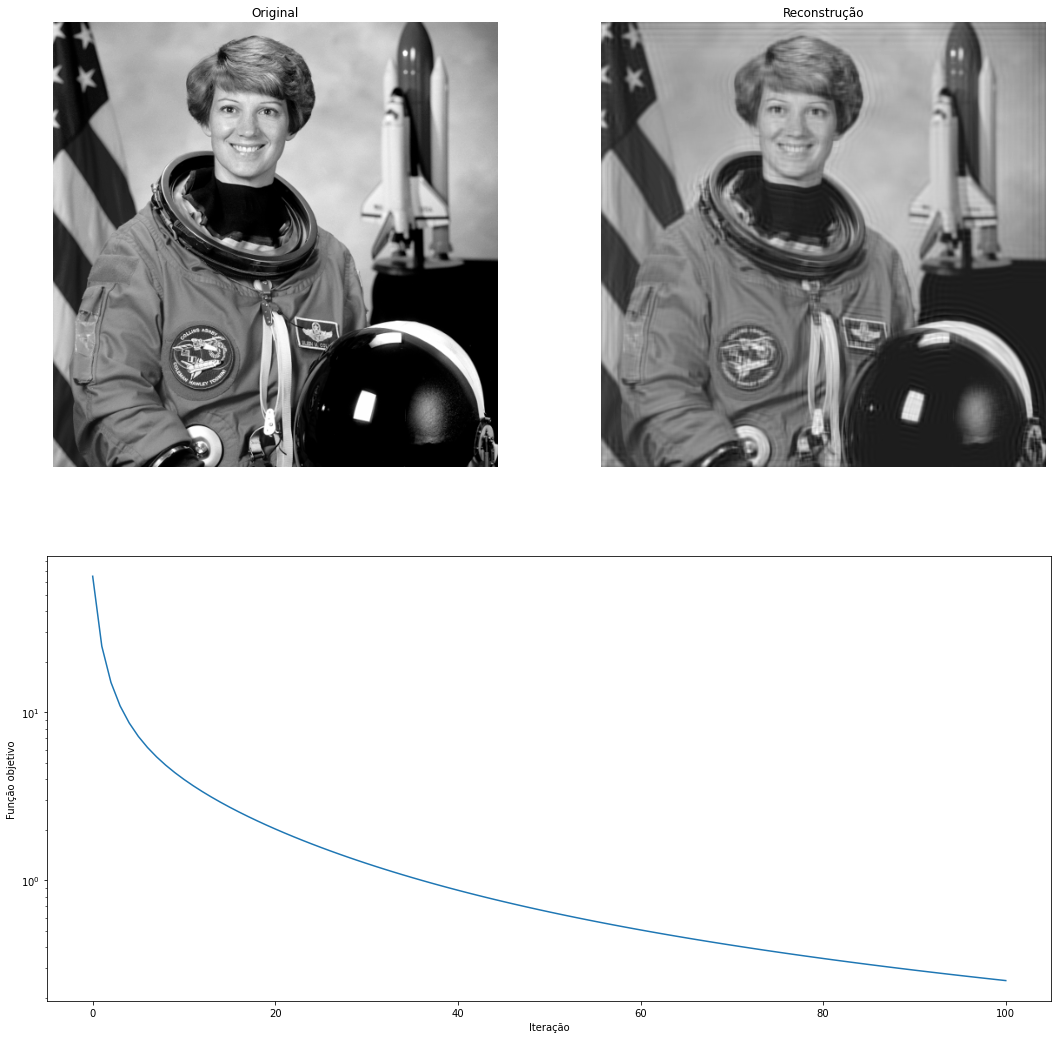

In [ ]:
pp.figure( figsize = ( 18, 18 ) )

pp.subplot( 2, 2, 1 )
pp.imshow( img, cmap = pp.cm.gray )
pp.title( 'Original' )
pp.axis( 'off' )

pp.subplot( 2, 2, 2 )
pp.imshow( iters[ -1 ], cmap = pp.cm.gray )
pp.title( 'Reconstrução' )
pp.axis( 'off' )

pp.subplot( 2, 1, 2 )
pp.semilogy( f_vals )
pp.xlabel( 'Iteração' )
pp.ylabel( 'Função objetivo' )
pp.axis( 'tight' )

pp.show()

In [ ]:
niter = 1000

iters = md( grad, b, 1.0, niter )

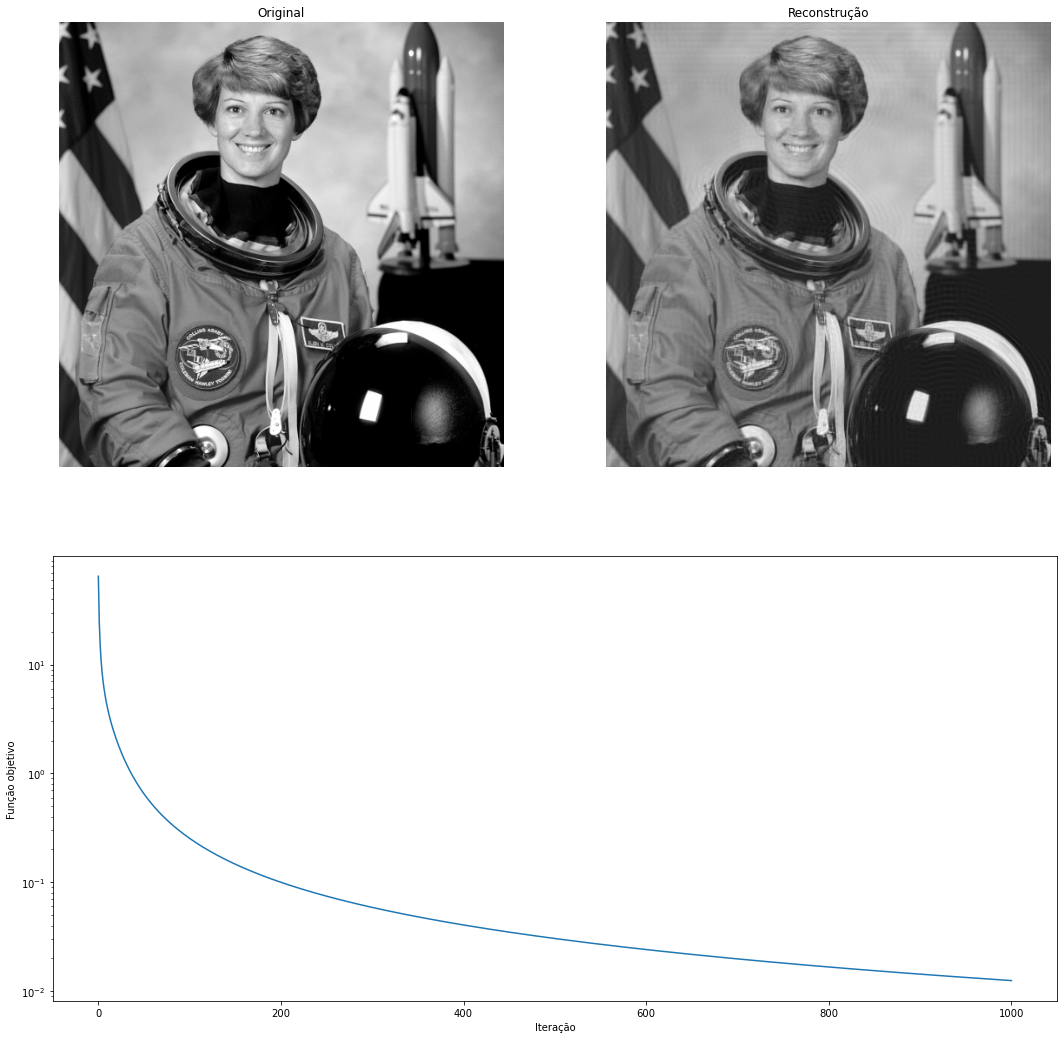

In [ ]:
f_vals = [ f( x ) for x in iters ]

pp.figure( figsize = ( 18, 18 ) )

pp.subplot( 2, 2, 1 )
pp.imshow( img, cmap = pp.cm.gray )
pp.title( 'Original' )
pp.axis( 'off' )

pp.subplot( 2, 2, 2 )
pp.imshow( iters[ -1 ], cmap = pp.cm.gray )
pp.title( 'Reconstrução' )
pp.axis( 'off' )

pp.subplot( 2, 1, 2 )
pp.semilogy( f_vals )
pp.xlabel( 'Iteração' )
pp.ylabel( 'Função objetivo' )
pp.axis( 'tight' )

pp.show()